[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jalonso1979/puremacro/blob/main/curso/notebooks/T01_B_measurement_and_cycles_es.ipynb)

> **Nota para Google Colab**: la celda siguiente instala `puremacro` y, si hace falta, descarga del repositorio público [jalonso1979/puremacro](https://github.com/jalonso1979/puremacro) sólo la carpeta `curso/notebooks` (auxiliares, datos congelados y modelos). No pide acceso a Google Drive.

[A: Datos](T01_A_data_panels_es.ipynb) · [B: Medición y ciclo](T01_B_measurement_and_cycles_es.ipynb) · [C: Hechos estilizados](T01_C_stylized_facts_es.ipynb)

In [1]:
# Configuración del entorno: Google Colab, instalación local o Juno (iPad)
import os
import sys
from pathlib import Path

def _safe_probe(p, is_dir=None):
    """¿Existe la ruta? Sin lanzar OSError/PermissionError en el sandbox de Juno."""
    try:
        p = Path(p)
        if is_dir is True:
            return p.is_dir()
        if is_dir is False:
            return p.is_file()
        return p.exists()
    except (OSError, PermissionError, TypeError, ValueError):
        return False

if "google.colab" in sys.modules:
    !pip install -q "puremacro>=4.8.1,<5"
    if not _safe_probe(Path.cwd() / "_nbstyle.py", is_dir=False):
        # Clon parcial del repositorio público: sólo curso/notebooks, sin historia
        _repo = Path("/content/puremacro")
        if not _safe_probe(_repo, is_dir=True):
            !git clone -q --depth 1 --filter=blob:none --sparse https://github.com/jalonso1979/puremacro.git {_repo}
        !git -C {_repo} sparse-checkout set curso/notebooks 2>&1 | tail -n 2
        os.chdir(_repo / "curso/notebooks")

# Carpeta con los auxiliares del curso (_nbstyle, _datos) en sys.path, sin salir del sandbox
_candidatos = [Path.cwd(), Path.cwd() / "notebooks", Path.cwd() / "curso/notebooks"]
try:
    _candidatos.insert(0, Path(__file__).resolve().parent)  # Juno define __file__
except (NameError, OSError):
    pass
for _c in _candidatos:
    if _safe_probe(_c / "_nbstyle.py", is_dir=False):
        if str(_c) not in sys.path:
            sys.path.insert(0, str(_c))
        break

# Gráficas en línea y estilo del curso
%matplotlib inline
try:
    import _nbstyle
    _nbstyle.apply_style()
except ImportError:
    pass

# Módulo 1B — Medición, vintages y posición en el ciclo

**Curso complementario · puremacro**

A entrega observaciones, no una brecha del producto. ¿Un cambio del PIB medido refleja contabilidad, revisión o un cambio económico? ¿Habría podido ver la señal un responsable de política en ese momento?

### Objetivos de aprendizaje
1. Auditar identidades real/nominal, ajuste estacional, unidades laborales y agregación temporal.
2. Distinguir períodos de referencia de fechas de vintage; estimar las dos regresiones de revisión de **Mankiw–Shapiro (1986)** sobre crecimientos.
3. Comparar HP, Hamilton, Baxter–King, Christiano–Fitzgerald y primeras diferencias, incluidos sus distintos extremos y objetos medidos.
4. Separar revisiones causadas por los datos de las causadas por el extremo de la muestra del filtro.
5. Leer conjuntamente PIB, producción industrial y desempleo, usando la **regla de Sahm** como señal estadounidense y diagnóstico internacional explícitamente exploratorio.

**Ruta:** medición → vintages → filtros → incertidumbre en tiempo real → tablero del ciclo. Fijamos así las decisiones que utilizará **C** para evaluar hechos estilizados. Todos los resultados usan datos congelados. Imprimimos la última fecha de cada archivo, sin suponer que es hoy.

In [2]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import _nbstyle
from _datos import ruta_dato
from _t01 import CONTRACT, load_panel, wide_panel, coverage, regular_block
_nbstyle.apply_style()
cols = _nbstyle.palette(6)
LANG = "es"
def tr(en, es):
    return es if LANG == "es" else en
manifest = json.loads(ruta_dato("t01_manifest.json").read_text())
print(tr("Snapshot assembly (UTC):", "Ensamblado de las copias (UTC):"), manifest["assembled_utc"])

Ensamblado de las copias (UTC): 2026-10-07T23:48:52.985790+00:00


In [3]:
q = wide_panel(load_panel("Q", variables=CONTRACT["Q"]))  # the quarterly series T01_A promises B and C
q = q[q.gdp.notna().groupby(level="code").transform("any")]  # economies with quarterly national accounts
m = wide_panel(load_panel("M", variables=["ip", "urate"]))  # the two monthly series this notebook reads
for v in ["gdp", "cons_hh", "cons_gov", "inv", "capform", "exports", "imports"]:
    q[v + "_real"] = 100 * q[v] / q[v + "_defl"]
from puremacro.data import hp_filter
from puremacro.cycles import hamilton_filter, baxter_king_filter, christiano_fitzgerald_filter

## 1. Qué se mide: identidades, precios y trabajo

A precios corrientes la identidad utiliza **formación bruta de capital** (inversión fija más inventarios y objetos valiosos), no sólo inversión fija:
$$Y^N=C^N+G^N+I^N_{\rm total}+X^N-M^N.$$
Los volúmenes encadenados en general no suman. Un año de referencia común cambia niveles de índices; no restaura aditividad ni comparabilidad de poder de compra. Reclasificar duraderos también mueve $\sigma(c)/\sigma(y)$ sin cambiar la conducta de los hogares.

Una jornada plausible es un diagnóstico, no prueba suficiente de una corrección de unidades. El complemento documenta la contrastación de fuentes. Aquí `hours_factor` informa qué reparaciones ya se aplicaron. Medir la economía entera o el sector de mercado son decisiones distintas, particularmente al comparar productividad de EUA/Japón.

In [4]:
identity = q[["gdp", "cons_hh", "cons_gov", "capform", "exports", "imports"]].dropna()
identity["residual_pct"] = 100*(identity.gdp - identity.cons_hh - identity.cons_gov
                                - identity.capform - identity.exports + identity.imports)/identity.gdp
vr = q[[v + "_real" for v in ["gdp", "cons_hh", "cons_gov", "capform", "exports", "imports"]]].dropna()
vr["residual_pct"] = 100*(vr.gdp_real-vr.cons_hh_real-vr.cons_gov_real-vr.capform_real-vr.exports_real+vr.imports_real)/vr.gdp_real
display(pd.DataFrame({"nominal_abs_residual_pct": identity.residual_pct.abs().groupby("code").median(),
                      "volume_abs_residual_pct": vr.residual_pct.abs().groupby("code").median()}).round(3))
repairs = q.hours_factor.groupby("code").first().dropna()
display(repairs[repairs.ne(1)].rename("stored_hours_factor").to_frame())
print(tr("Residuals are measurements to inspect, not an excuse to force the accounts to close.",
         "Los residuos se inspeccionan; no justifican forzar el cierre de las cuentas."))

,nominal_abs_residual_pct,volume_abs_residual_pct
code,,
ARG,0.448,0.478
ARM,1.263,NaN
AUS,0.335,0.825
AUT,0.322,0.407
BEL,0.000,0.160
BGR,0.404,1.223
BIH,8.637,4.545
BRA,0.665,0.220
CAN,0.087,0.254


,stored_hours_factor
code,
CHL,13.0


Los residuos se inspeccionan; no justifican forzar el cierre de las cuentas.


### 1.1 La agregación puede crear persistencia

En un paseo aleatorio mensual, el crecimiento de medias trimestrales no solapadas tiene autocorrelación de orden uno $4/19$, aunque los incrementos mensuales sean independientes. El crecimiento entre cierres trimestrales no presenta ese efecto particular del promedio. La simulación es explícitamente sintética: explica un mecanismo de medición, no un hecho de un país.

El ajuste estacional es otra cuestión. Los metadatos QNA distinguen ajuste del proveedor y del curso. Las diferencias interanuales pueden quitar estacionalidad estable, pero introducen observaciones solapadas y no sustituyen un procedimiento documentado de desestacionalización.

In [5]:
rng = np.random.default_rng(20261004)
walk = np.cumsum(rng.normal(size=300000)).reshape(-1, 3)
working = pd.Series(walk.mean(axis=1)).diff().autocorr()
end_month = pd.Series(walk[:, -1]).diff().autocorr()
display(pd.Series({"quarterly averages": working, "quarter-end observations": end_month,
                   "theory: 4/19": 4/19}, name="rho_1").to_frame())
assert abs(working - 4/19) < .02 and abs(end_month) < .02

,rho_1
quarterly averages,0.211630
quarter-end observations,0.000457
theory: 4/19,0.210526


## 2. Dos fechas: el trimestre y la edición

Escribimos $y_t^{(v)}$: trimestre de referencia $t$, edición del archivo $v$. Un archivo de última publicación sólo tiene una columna de ese triángulo y no reconstruye la información disponible en 2008. El archivo OCDE tiene ediciones mensuales, no las fechas exactas de primera publicación oficial. **Primera observación disponible en este archivo** es la descripción defendible del dato preliminar.

Conservamos todas las ediciones, detectamos contaminación estacional y aplicamos el mismo ajuste con ficticias trimestrales dentro de cada edición. Los coeficientes usan sólo observaciones presentes en esa edición (ventana anterior a 2020 cuando existe). Evitamos borrar ediciones tempranas sin ajustar y ascender una revisión de años después a «primera publicación». Es un ajuste docente transparente, no un sustituto de los efectos de calendario y atípicos de X-13. El complemento conserva esa contrastación y las pruebas de revisión de nueve componentes.

In [6]:
from puremacro.fetch.realtime import VintagePanel, seasonal_signature, SEASONAL_WINDOW, SEASONAL_MIN_OBS
raw = pd.read_csv(ruta_dato("oecd_stes_vintages_gdp.csv.gz"), dtype={"edition": str})
vintage_data = pd.DataFrame({
    "country": raw.code.astype(str), "variable": raw.variable.astype(str),
    "date": pd.PeriodIndex(raw.date.astype(str), freq="Q").to_timestamp(),
    "vintage": pd.to_datetime(raw.edition, format="%Y%m"), "value": raw.value,
    "provider": pd.Categorical(["oecd_stes"]*len(raw)),
    "series_id": pd.Categorical(raw.code.astype(str) + ".Q.B1GQ_Q"),
    "units": pd.Categorical(["level"]*len(raw)),
})
raw_panel = VintagePanel(df=vintage_data)
print(tr("Archive coverage:", "Cobertura del archivo:"))
display(raw_panel.coverage().head())

Cobertura del archivo:


,country,variable,provider,series_id,n_obs,n_vintages,n_periods,first_date,last_date,first_vintage,last_vintage
0,AUS,gdp_real,oecd_stes,AUS.Q.B1GQ_Q,68505,331,267,1959-07-01,2026-01-01,1999-02-01,2026-08-01
1,AUT,gdp_real,oecd_stes,AUT.Q.B1GQ_Q,27680,331,250,1964-01-01,2026-04-01,1999-02-01,2026-08-01
2,BEL,gdp_real,oecd_stes,BEL.Q.B1GQ_Q,27397,331,186,1980-01-01,2026-04-01,1999-02-01,2026-08-01
3,BRA,gdp_real,oecd_stes,BRA.Q.B1GQ_Q,21347,263,141,1991-01-01,2026-01-01,2004-09-01,2026-08-01
4,CAN,gdp_real,oecd_stes,CAN.Q.B1GQ_Q,58150,331,262,1961-01-01,2026-04-01,1999-02-01,2026-08-01


In [7]:
def deseasonalize_editions(p, sig=None, window=SEASONAL_WINDOW,
                           min_obs=SEASONAL_MIN_OBS):
    """Adjust every edition independently, retaining all rows; return panel and receipt."""
    lo, hi = pd.Timestamp(window[0]), pd.Timestamp(window[1])
    pieces, short_n = [], 0
    for (country, var), sub in p.df.groupby(["country", "variable"], sort=True):
        piv = (sub.pivot_table(index="date", columns="vintage", values="value")
                  .sort_index())
        lg = np.log(piv)
        g = lg.diff()
        q = pd.Index(g.index.quarter)
        inside = (g.index >= lo) & (g.index < hi)
        qi = q[inside]
        m = g[inside].groupby(qi).mean().reindex([1, 2, 3, 4])
        n_q = g[inside].groupby(qi).count().reindex([1, 2, 3, 4]).fillna(0)
        # The very few editions that do not reach min_obs inside the window —
        # the earliest ones, ending in 1998 — are estimated on their whole
        # sample, which for them is entirely pre-pandemic anyway.
        short = n_q.sum() < min_obs
        if short.any():
            whole = g.groupby(q).mean().reindex([1, 2, 3, 4])
            mask = short.to_numpy()
            m.loc[:, mask] = whole.loc[:, mask]
            short_n += int(short.sum())
        m = m.fillna(0.0)
        m = m - m.mean(axis=0)      # centred: the profile goes, the mean stays
        factor = m.cumsum()          # periodic by construction: factor[4] = 0
        key = pd.MultiIndex.from_arrays(
            [sub["date"].dt.quarter, sub["vintage"]])
        pieces.append(sub.assign(
            value=sub["value"].to_numpy()
            * np.exp(-factor.stack().reindex(key).to_numpy())))
    out = pd.concat(pieces, ignore_index=True)
    adjusted = VintagePanel(df=out,
                            metadata={**p.metadata,
                                      "seasonal": "quarterly dummies within edition",
                                      "short_editions": short_n})
    # `sig` arrives ready-made because the cell already computed it for the
    # screen: scoring eleven thousand editions twice is a quarter of a second on
    # a desktop and considerably more on a tablet, for exactly the same numbers.
    before = seasonal_signature(p) if sig is None else sig
    after = seasonal_signature(adjusted)
    receipt = pd.concat(
        [before.groupby("country")["seasonal_range"].max().rename("range_before"),
         after.groupby("country")["seasonal_range"].max().rename("range_after"),
         before.groupby("country")["unadjusted"].sum().rename("flagged")],
        axis=1)
    return adjusted, receipt

In [8]:
signature = seasonal_signature(raw_panel)
vintages, seasonal_receipt = deseasonalize_editions(raw_panel, sig=signature)
assert len(vintages.df) == len(raw_panel.df)
print(tr("Editions flagged / all editions:", "Ediciones marcadas / todas las ediciones:"),
      int(signature.unadjusted.sum()), "/", raw_panel.df.groupby(["country", "vintage"]).ngroups)
display(seasonal_receipt.sort_values("range_before", ascending=False).head(10).round(3))
triangle = vintages.triangle("MEX", transform="log_diff_pct")
display(triangle.loc["2008":"2009"].iloc[:, -8:].round(2))
# Free the unadjusted copies before estimating the international panel.
del raw, vintage_data, raw_panel

Ediciones marcadas / todas las ediciones: 501 / 11503


,range_before,range_after,flagged
country,,,
TUR,61.754,0.0,76
CZE,29.778,0.0,38
SWE,28.691,0.0,76
POL,22.843,0.0,53
HUN,19.636,0.0,24
AUT,17.747,0.0,48
ISL,16.671,0.0,30
SVK,12.784,0.0,56
MEX,10.834,0.0,72


vintage,2025-11-01,2025-12-01,2026-01-01,2026-02-01,2026-05-01,2026-06-01,2026-07-01,2026-08-01
date,,,,,,,,
2008-01-01,0.30,0.25,0.25,0.25,0.25,0.23,0.23,0.23
2008-04-01,0.92,0.99,0.99,0.99,0.99,1.01,1.01,1.01
2008-07-01,-0.20,-0.23,-0.23,-0.23,-0.23,-0.24,-0.24,-0.24
2008-10-01,-1.83,-1.81,-1.81,-1.81,-1.81,-1.80,-1.80,-1.80
2009-01-01,-6.10,-6.08,-6.08,-6.08,-6.09,-6.09,-6.09,-6.09
2009-04-01,-1.41,-1.46,-1.46,-1.46,-1.45,-1.46,-1.46,-1.46
2009-07-01,3.24,3.26,3.26,3.26,3.26,3.26,3.26,3.26
2009-10-01,1.93,1.94,1.94,1.94,1.94,1.95,1.95,1.95


### 2.1 Mankiw–Shapiro: noticias, ruido, ambos o ninguno

Usamos crecimiento logarítmico trimestral calculado **dentro de cada edición**, no diferencias de niveles entre vintages con distinto año base. Sean $p_t$ el primer crecimiento observado, $f_t$ el último disponible y $r_t=f_t-p_t$.

$$r_t=\alpha_N+\beta_Np_t+e_t,\qquad r_t=\alpha_E+\beta_Ef_t+u_t.$$

Noticias puras sin sesgo implican $(\alpha_N,\beta_N)=(0,0)$; ruido puro sin sesgo implica $(\alpha_E,\beta_E)=(0,0)$. Informamos ambas pruebas de pendiente, la revisión media y **pruebas Wald HAC conjuntas de intercepto y pendiente**. No rechazar significa compatibilidad con una restricción, no demuestra que las revisiones sean sólo noticias o sólo ruido. Rechazar ambas permite mezclas y sesgo.

Para reducir censura izquierda y «finales» inmaduros, retenemos primeras apariciones 1–6 meses después del trimestre y exigimos al menos 12 meses entre primera y última estimación. La última cifra aún es revisable. Retenemos después el mayor tramo contiguo (al menos 24 trimestres), para que los rezagos HAC respeten el calendario. Mostramos las exclusiones. [Mankiw y Shapiro (1986)](https://www.nber.org/papers/w1939).

In [9]:
from scipy.stats import chi2
from puremacro.vintages import mankiw_shapiro

def joint_hac_pvalue(revision, regressor):
    y, x = np.asarray(revision), np.asarray(regressor)
    X = np.column_stack([np.ones(len(y)), x])
    beta = np.linalg.lstsq(X, y, rcond=None)[0]
    score = X*(y-X@beta)[:, None]
    bandwidth = int(np.floor(4*(len(y)/100)**(2/9)))
    meat = score.T@score
    for lag in range(1, bandwidth+1):
        cross = score[lag:].T@score[:-lag]
        meat += (1-lag/(bandwidth+1))*(cross+cross.T)
    bread = np.linalg.inv(X.T@X)
    cov = bread@meat@bread * len(y)/(len(y)-X.shape[1])
    return float(chi2.sf(beta@np.linalg.pinv(cov)@beta, 2))

def mature_pairs(one, country):
    tri = one.triangle(country, transform="log_diff_pct")
    rows = []
    for date, values in tri.iterrows():
        values = values.dropna()
        if len(values) < 2:
            continue
        first, last = values.index[0], values.index[-1]
        lag = first.to_period("M").ordinal - date.to_period("Q").asfreq("M", "end").ordinal
        mature = (last.to_period("M").ordinal-first.to_period("M").ordinal) >= 12
        if 1 <= lag <= 6 and mature:
            rows.append({"date":date, "preliminary":values.iloc[0], "final":values.iloc[-1]})
    return pd.DataFrame(rows), len(tri)

rows = []
for country, data in vintages.df.groupby("country", sort=True):
    if country == "EA20":  # an aggregate, not one more independent country
        continue
    pairs, total = mature_pairs(VintagePanel(df=data), country)
    eligible = len(pairs)
    block = (regular_block(pairs.set_index("date"), ["preliminary", "final"], min_obs=24)
             if not pairs.empty else None)
    pairs = block if block is not None else pairs.iloc[:0]
    row = {"code": country, "candidate_quarters": total, "eligible_mature_pairs": eligible, "n": len(pairs), "excluded": total-len(pairs)}
    if len(pairs) >= 24:
        result = mankiw_shapiro(pairs.preliminary, pairs.final, hac_lags="auto", transform="log_diff_pct")
        revision = pairs.final-pairs.preliminary
        pn = joint_hac_pvalue(revision, pairs.preliminary)
        pe = joint_hac_pvalue(revision, pairs.final)
        row.update(mean_revision=result.mean_revision, p_bias=result.p_mean_revision,
                   beta_preliminary=result.beta_on_preliminary, p_slope_news=result.p_beta_on_preliminary,
                   beta_final=result.beta_on_final, p_slope_noise=result.p_beta_on_final,
                   p_joint_news=pn, p_joint_noise=pe,
                   compatible=("both" if pn>=.05 and pe>=.05 else "news" if pn>=.05 else "noise" if pe>=.05 else "neither"))
    else:
        row["compatible"] = "insufficient observations"
    rows.append(row)
ms = pd.DataFrame(rows).set_index("code")
display(ms.round(3))
display(ms.compatible.value_counts().rename("countries").to_frame())
assert (ms.n + ms.excluded == ms.candidate_quarters).all()

,candidate_quarters,eligible_mature_pairs,n,excluded,mean_revision,p_bias,beta_preliminary,p_slope_news,beta_final,p_slope_noise,p_joint_news,p_joint_noise,compatible
code,,,,,,,,,,,,,
AUS,267,107,107,160,0.090,0.002,-0.057,0.120,0.050,0.274,0.001,0.001,neither
AUT,250,107,107,143,0.071,0.187,-0.032,0.707,0.152,0.005,0.432,0.001,news
BEL,186,107,106,80,0.147,0.002,-0.065,0.012,-0.010,0.828,0.000,0.002,neither
BRA,141,84,56,85,0.061,0.267,-0.040,0.071,0.057,0.414,0.171,0.241,both
CAN,262,108,108,154,0.067,0.023,-0.070,0.000,-0.027,0.619,0.000,0.085,noise
CHE,185,107,107,78,0.155,0.003,-0.171,0.000,0.037,0.844,0.000,0.001,neither
CHL,125,62,62,63,0.021,0.675,-0.072,0.005,-0.024,0.206,0.015,0.375,noise
COL,85,22,0,85,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,insufficient observations
CRI,142,20,0,142,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,insufficient observations


,countries
compatible,
neither,15
noise,9
both,8
news,7
insufficient observations,2


**Leer las pruebas.** Compara pendientes y pruebas conjuntas antes de contar una historia de «noticias o ruido»: una revisión media distinta de cero puede rechazar ausencia de sesgo aunque sobreviva la restricción de pendiente. Los conteos entre países son descriptivos; decenas de pruebas al 5% generan multiplicidad. Cambia madurez y primera aparición antes de tratar la clasificación como robusta. El complemento conserva la especificación original de todo el archivo y muestra por qué tirar ediciones sin ajustar cambia la pregunta.

## 3. Los filtros responden preguntas distintas

Sea $x_t=100\log Y_t$. HP elige una tendencia suave minimizando
$$\sum_t(x_t-\tau_t)^2+\lambda\sum_t(\Delta^2\tau_t)^2.$$
Aquí usamos $\lambda=1600$ trimestral; hay que especificar la frecuencia. Hamilton regresa $x_t$ sobre una constante y $x_{t-8},\ldots,x_{t-11}$. BK aproxima la banda de 6–32 trimestres y pierde 12 observaciones en cada extremo. CF aproxima esa banda bajo sus supuestos de paseo aleatorio y conserva extremos revisables. Primeras diferencias miden **crecimiento**, no brecha del producto.

Los coeficientes Hamilton estimados con toda la muestra usan observaciones futuras para residuos tempranos, aunque los regresores sean rezagos. HP bilateral y CF también miran al futuro. Devolver una cifra al final no convierte un método en estimador en tiempo real ni estructural del producto potencial. [Hamilton (2018)](https://www.nber.org/papers/w23429).

,n,first,last,sd_common_window
HP,100,1995-01-01,2019-10-01,1.966962
Hamilton,89,1997-10-01,2019-10-01,3.692804
BK,76,1998-01-01,2016-10-01,1.819951
CF,100,1995-01-01,2019-10-01,1.909033


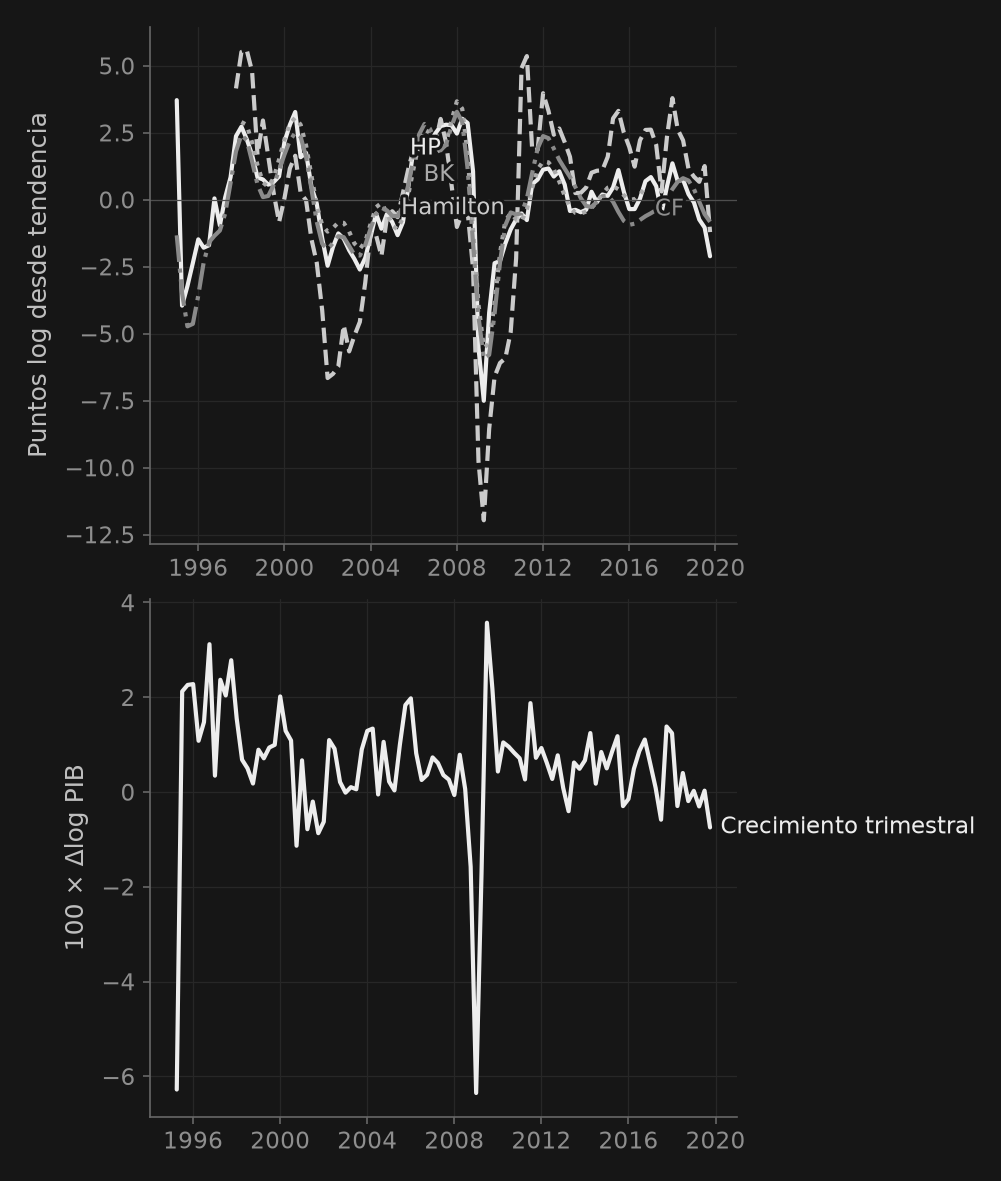

In [10]:
country = "MEX"  # ← compare the same country and window under every method
sample = regular_block(q.loc[country], ["gdp_real"], start="1995", end="2019", min_obs=60)
x = 100*np.log(sample.gdp_real)
filtered = pd.DataFrame({
    "HP": hp_filter(x, lamb=1600)[0],
    "Hamilton": hamilton_filter(x, h=8, p=4)[0],
    "BK": baxter_king_filter(x, low=6, high=32, K=12)[0],
    "CF": christiano_fitzgerald_filter(x, low=6, high=32)[0],
})
common = filtered.dropna()
display(pd.DataFrame({"n": filtered.count(), "first": filtered.apply(lambda s:s.first_valid_index()),
                      "last": filtered.apply(lambda s:s.last_valid_index()),
                      "sd_common_window": common.std()}))
fig, axes = _nbstyle.figura(2, 1)
for j, name in enumerate(filtered):
    axes[0].plot(filtered.index, filtered[name], color=cols[j], ls=["-","--",":","-."][j], label=name)
axes[0].axhline(0, color=cols[-1], lw=.6)
axes[0].set_ylabel(tr("Log points from trend", "Puntos log desde tendencia"))
_nbstyle.etiquetar(axes[0])
axes[1].plot(x.index, x.diff(), color=cols[0], label=tr("Quarterly growth", "Crecimiento trimestral"))
axes[1].set_ylabel(tr("100 × Δlog GDP", "100 × Δlog PIB"))
_nbstyle.etiquetar(axes[1]); plt.show()

### 3.1 Un filtro puede fabricar ciclos aparentes

Una serie integrada no tiene una «brecha verdadera» observada sólo porque sus innovaciones de crecimiento sean independientes. Filtrar un paseo aleatorio puede producir un residuo persistente; esa persistencia no valida por sí sola un mecanismo de propagación RBC. Hay que aplicar las mismas decisiones de medición y filtrado al modelo y a los datos antes de calibrar momentos.

In [11]:
rng = np.random.default_rng(142)
synthetic = pd.Series(np.cumsum(rng.normal(size=400)))
synthetic_hp = pd.Series(hp_filter(synthetic, lamb=1600)[0])
display(pd.Series({"innovation rho_1": synthetic.diff().autocorr(),
                   "HP residual rho_1": synthetic_hp.autocorr()}, name="synthetic_example").to_frame())

,synthetic_example
innovation rho_1,-0.026139
HP residual rho_1,0.642411


## 4. ¿Podía conocerse la brecha entonces?

En el último trimestre $t$ disponible de una edición, calculamos tres brechas HP con el mismo comienzo:

- $g_t^{RT}$: esa edición, terminada en $t$.
- $g_t^{P}$: última edición truncada en $t$ (seudotiempo real).
- $g_t^{F}$: última edición incluyendo las observaciones posteriores.

Así, $g_t^F-g_t^{RT}=(g_t^P-g_t^{RT})+(g_t^F-g_t^P)$. El primer componente incluye revisiones de datos y del ajuste estacional dentro de la edición; el segundo fija los datos y extiende la muestra del filtro. Sus varianzas no suman sin el término de covarianza. Es una descomposición **estadística**, no una medición estructural del potencial. [El problema de tiempo real de Orphanides y van Norden](https://www.federalreserve.gov/pubs/feds/2012/201286/index.html).

,quarter,real_time,pseudo,full,data_revision,endpoint_revision,total_revision
edition,,,,,,,
2025-10-01,2025-04-01,-0.09,-0.25,0.30,-0.17,0.56,0.39
2025-11-01,2025-07-01,-0.99,-0.92,-0.52,0.06,0.40,0.46
2025-12-01,2025-07-01,-1.10,-0.92,-0.52,0.17,0.40,0.57
2026-01-01,2025-07-01,-1.10,-0.92,-0.52,0.17,0.40,0.57
2026-02-01,2025-07-01,-1.10,-0.92,-0.52,0.17,0.40,0.57
2026-05-01,2025-10-01,-0.52,-0.74,-0.47,-0.22,0.27,0.05
2026-06-01,2026-01-01,-1.25,-1.25,-1.26,0.00,-0.01,-0.01
2026-07-01,2026-01-01,-1.25,-1.25,-1.26,0.00,-0.01,-0.01


,data_revision,endpoint_revision,total_revision
mean,0.26,-0.27,-0.01
std,0.53,2.00,1.90


Desacuerdo de signo: 47.0 %


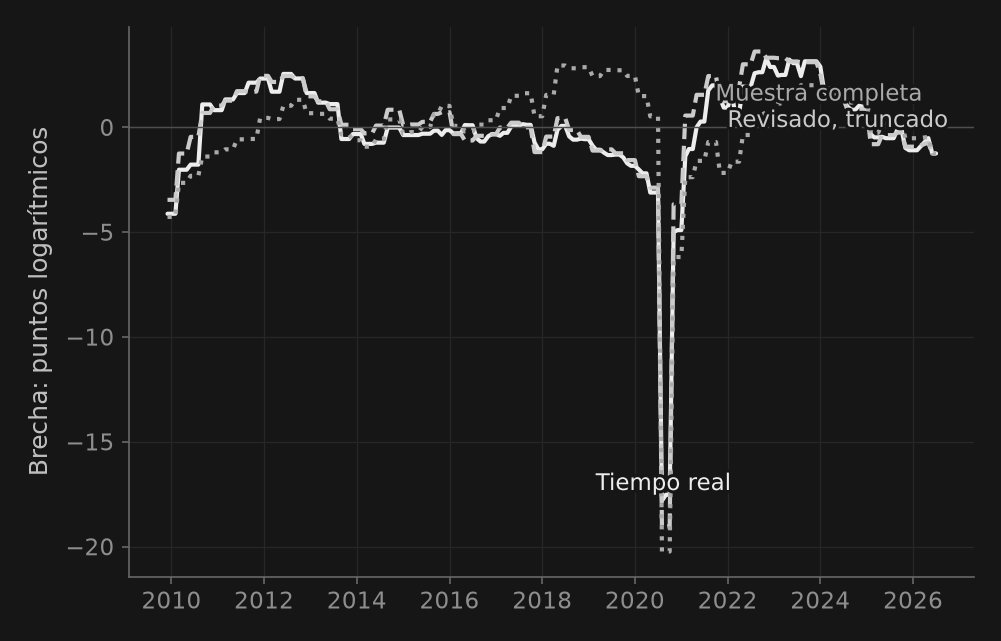

In [12]:
rt_country = "MEX"  # ← this exercise can be repeated for every archived country
levels = vintages.triangle(rt_country, transform="level")
latest = levels.iloc[:, -1].dropna()
records = []
for edition in levels.columns:
    observed = levels[edition].dropna()
    if len(observed) < 40 or observed.index.max() >= latest.index.max():
        continue
    dates = pd.date_range(observed.index.min(), observed.index.max(), freq="QS")
    rt = observed.reindex(dates)
    pseudo = latest.reindex(dates)
    full = latest.loc[dates.min():].asfreq("QS")
    if rt.isna().any() or pseudo.isna().any() or full.isna().any():
        continue
    t = dates[-1]
    grt = float(np.asarray(hp_filter(100*np.log(rt), lamb=1600)[0])[-1])
    gp = float(np.asarray(hp_filter(100*np.log(pseudo), lamb=1600)[0])[-1])
    gf = float(hp_filter(100*np.log(full), lamb=1600)[0].loc[t])
    records.append({"edition":edition,"quarter":t,"real_time":grt,"pseudo":gp,"full":gf,
                    "data_revision":gp-grt,"endpoint_revision":gf-gp,"total_revision":gf-grt})
revision_gap = pd.DataFrame(records).set_index("edition")
assert np.allclose(revision_gap.total_revision, revision_gap.data_revision+revision_gap.endpoint_revision)
display(revision_gap.tail(8).round({col:2 for col in revision_gap.tail(8).select_dtypes("number")}))
display(revision_gap[["data_revision","endpoint_revision","total_revision"]].agg(["mean","std"]).round(2))
print(tr("Sign disagreement:", "Desacuerdo de signo:"),
      round(100*np.mean(np.sign(revision_gap.real_time)!=np.sign(revision_gap.full)),1), "%")
fig, ax = _nbstyle.figura(1, 1)
for j, col in enumerate(["real_time", "pseudo", "full"]):
    ax.plot(revision_gap.index, revision_gap[col], color=cols[j], ls=["-","--",":"][j], label={"real_time":tr("Real time","Tiempo real"), "pseudo":tr("Revised, truncated","Revisado, truncado"), "full":tr("Full sample","Muestra completa"), "current":tr("Current vintage","Vintage actual")}[col])
ax.axhline(0, color=cols[-1], lw=.7)
ax.set_ylabel(tr("Output gap: log points", "Brecha: puntos logarítmicos"))
_nbstyle.etiquetar(ax); plt.show()

## 5. La señal de Sahm y el conjunto de información

Para desempleo mensual **en puntos porcentuales**, definimos
$$\bar u_t=\tfrac13(u_t+u_{t-1}+u_{t-2}),\qquad S_t=\bar u_t-\min_{j=1,\ldots,12}\bar u_{t-j}.$$
La señal estadounidense se activa con $S_t\geq0.50$ puntos porcentuales. El mínimo anterior excluye el mes corriente; no redondeamos antes del umbral. Hay que reindexar a meses del calendario antes de las medias móviles: los huecos acortan de otro modo la ventana efectiva.

Mide un cambio del desempleo, no el nivel de holgura, y no constituye una declaración oficial de recesión. Aplicar el mismo umbral a otros países es exploratorio, no una regla universal validada. Contrastamos el cálculo con **SAHMCURRENT** y lo comparamos con **SAHMREALTIME**, que utiliza el conjunto de información histórico. [Definición FRED con datos actuales](https://fred.stlouisfed.org/series/SAHMCURRENT), [definición en tiempo real](https://fred.stlouisfed.org/series/SAHMREALTIME).

Error máximo de reconstrucción (pp): 0.003333


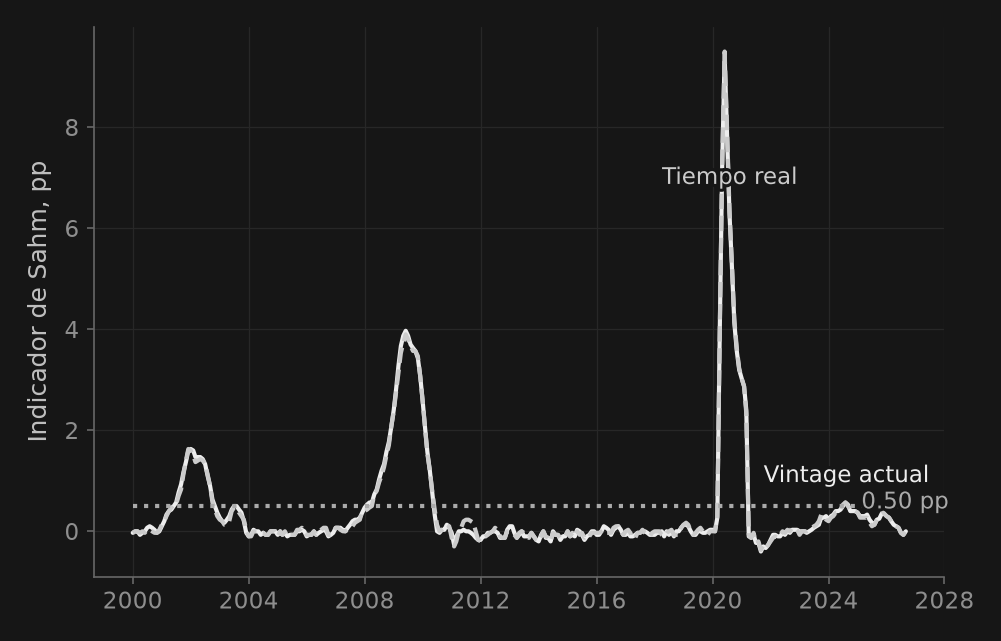

,calculated,current,real_time
2026-04-01,NaN,0.13,0.13
2026-05-01,NaN,0.10,0.10
2026-06-01,NaN,0.07,0.07
2026-07-01,NaN,-0.03,-0.03
2026-08-01,NaN,-0.07,-0.07
2026-09-01,NaN,0.00,0.00


In [13]:
from _t01 import sahm

def fred_snapshot(series):
    d = pd.read_csv(ruta_dato("t01_"+series+".csv"), parse_dates=["observation_date"])
    return pd.to_numeric(d.set_index("observation_date")[series], errors="coerce").asfreq("MS")
u = fred_snapshot("UNRATE")
sahm_check = pd.concat([sahm(u).rename("calculated"), fred_snapshot("SAHMCURRENT").rename("current"),
                        fred_snapshot("SAHMREALTIME").rename("real_time")], axis=1)
# FRED publishes the indicator to two decimals. Check with that publication tolerance.
max_error = (sahm_check.calculated-sahm_check.current).dropna().abs().max()
print(tr("Largest reconstruction error (pp):", "Error máximo de reconstrucción (pp):"), round(max_error,6))
assert max_error <= .011
fig, ax = _nbstyle.figura(1,1)
for j,col in enumerate(["current", "real_time"]):
    z = sahm_check.loc["2000":, col]
    ax.plot(z.index,z,color=cols[j],ls=["-","--"][j],label={"real_time":tr("Real time","Tiempo real"), "pseudo":tr("Revised, truncated","Revisado, truncado"), "full":tr("Full sample","Muestra completa"), "current":tr("Current vintage","Vintage actual")}[col])
ax.plot(z.index, np.full(len(z), .5), color=cols[2], ls=":", label="0.50 pp")
ax.set_ylabel(tr("Sahm indicator, pp", "Indicador de Sahm, pp"))
_nbstyle.etiquetar(ax);plt.show()
display(sahm_check.tail(6).round(3))

## 6. ¿Dónde estamos en el ciclo según estos archivos?

Leemos por separado **nivel respecto de tendencia estadística**, **crecimiento** y **deterioro laboral**. Una brecha HP negativa puede coexistir con crecimiento positivo; desempleo bajo puede coexistir con Sahm creciente. La producción industrial cubre menos que el PIB. No promediamos estos conceptos en una «puntuación del ciclo» sin definición.

El tablero usa la última observación utilizable de cada serie e imprime su fecha de referencia. Utiliza copias revisadas ensambladas para esta lección, **no** reconstruye la información de una fecha histórica de decisión. La brecha del PIB es una estimación en el extremo con los últimos datos y cambiará con la siguiente publicación. Los bordes mensuales pueden diferir entre países. No se deriva una inferencia causal ni una etiqueta automática de recesión.

In [14]:
rows = []
for c in sorted(set(q.index.get_level_values("code")) | set(m.index.get_level_values("code"))):
    row = {"code":c}
    if c in q.index.get_level_values("code"):
        b = regular_block(q.loc[c], ["gdp_real"], min_obs=40, which="latest")
        if b is not None:
            y=100*np.log(b.gdp_real)
            row.update(gdp_quarter=str(y.index[-1].to_period("Q")),
                       gdp_growth_qoq=float(y.diff().iloc[-1]),
                       hp_endpoint=float(np.asarray(hp_filter(y,lamb=1600)[0])[-1]))
    if c in m.index.get_level_values("code"):
        z=m.loc[c].asfreq("MS")
        ip_growth=100*np.log(z.ip).diff(12).dropna()
        ur=z.urate.dropna()
        signal=sahm(z.urate).dropna()
        if not ip_growth.empty:
            row.update(ip_month=str(ip_growth.index[-1].to_period("M")),ip_growth_yoy=ip_growth.iloc[-1])
        if not ur.empty:
            row.update(urate_month=str(ur.index[-1].to_period("M")),urate=ur.iloc[-1])
        if not signal.empty:
            row.update(sahm_month=str(signal.index[-1].to_period("M")),sahm_pp=signal.iloc[-1],
                       above_US_threshold=bool(signal.iloc[-1]>=.5-1e-12))
    rows.append(row)
dashboard=pd.DataFrame(rows).set_index("code")
with pd.option_context("display.max_rows", None):  # every economy on screen, not a truncated sample
    display(dashboard.round(2))
print(tr("Missing cells remain missing; reference dates differ. No universal recession classification.",
         "Los faltantes siguen faltando; las fechas difieren. No es una clasificación universal de recesiones."))

,gdp_quarter,gdp_growth_qoq,hp_endpoint,ip_month,ip_growth_yoy,urate_month,urate,sahm_month,sahm_pp,above_US_threshold
code,,,,,,,,,,
ALB,2026Q1,0.76,-0.38,2026-06,5.54,NaN,NaN,NaN,NaN,NaN
ARG,2026Q2,-0.59,0.09,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ARM,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AUS,2026Q2,0.42,-0.32,2021-01,3.67,2026-08,4.65,2026-08,0.36,False
AUT,2026Q2,-0.13,-0.49,2026-07,-1.91,2026-08,6.70,2026-08,0.50,True
BEL,2026Q2,0.03,-1.13,2026-07,-5.76,2026-08,5.90,2026-08,-0.03,False
BGR,2026Q2,0.66,-0.20,2026-07,-6.08,2026-08,3.50,2026-08,0.50,True
BIH,2026Q1,0.19,-1.05,2026-08,-0.23,2026-07,11.40,2026-07,0.00,False
BRA,2026Q2,0.48,-0.42,2026-08,-1.41,2015-11,8.01,2015-11,2.91,True


Los faltantes siguen faltando; las fechas difieren. No es una clasificación universal de recesiones.


### 6.1 Fechado y nowcasting van aquí; la identificación viene después

Fechar giros (por ejemplo, Bry–Boschan) clasifica picos y valles después de imponer duraciones; no estima una brecha. Un nowcast predice el trimestre corriente no observado con un panel mensual de borde irregular; no equivale a pronosticar el siguiente trimestre. Evaluar en tiempo real exige reconstruir datos, fechas de publicación y estimación de parámetros con información disponible. Truncar una serie revisada sólo produce un ejercicio en seudotiempo real.

El [complemento de frecuencias, §§1 y 4](T01_C_alta_frecuencia_es.ipynb) conserva los laboratorios de fechado y MIDAS/factores. Sus proyecciones locales e instrumentos monetarios posteriores son puentes opcionales a los módulos 3 y 5: la precedencia predictiva no identifica por sí sola un choque causal.

## 7. Tu turno

1. Reestima las pruebas de revisión con madurez de 24 meses. ¿Qué clasificaciones cambian? Separa sesgo y restricciones de pendiente.
2. Cambia México por España en filtros y vintages. Compara métodos en **fechas comunes** y explica por qué BK no diagnostica el último trimestre.
3. Escribe tres frases sobre un país: fechas observadas, qué dicen crecimiento y desempleo, y qué no permiten establecer.
4. Recalcula Sahm insertando un mes faltante y verifica que el hueco no se convierta silenciosamente en una observación adyacente.

### Soluciones (esquema)
Más madurez aporta revisiones a costa de muestra. BK pierde ambos extremos; Hamilton estimado una sola vez no produce una historia en tiempo real. El diagnóstico distingue nivel, crecimiento y deterioro laboral. Reindexar el calendario propaga el mes faltante por las ventanas necesarias.

### Explora con IA
Entrega al tutor una fila del tablero y pide una interpretación que nombre todas las fechas, distinga datos revisados de tiempo real y no afirme causalidad ni recesión oficial.

**Sigue:** [C — hechos estilizados de largo y corto plazo](T01_C_stylized_facts_es.ipynb). Ya tenemos una convención de medición explícita para los hechos que deberá explicar un modelo.